# Using your own aggregate data: which appliances are running?

Input: a CSV of whole-home power at ~1 Hz (`timestamp,watts`). Output: every step event with its ΔP,
predicted appliance and ON/OFF, plus the ON periods of each appliance.

The example file is a **held-out** day of REDD house 1 (after the model's training period), written as a
plain CSV by `scripts/check_predict_redd.py`. Replace `CSV` with your own file. The model must be trained
on the same home (`python scripts/train_model.py --house 1` for REDD).

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd
import matplotlib.pyplot as plt
from nilm.model import load_model
from nilm.inference import load_aggregate_csv, predict, save_outputs
pd.set_option("display.width", 160)

CSV = ROOT / "results/predict_check/redd_house1_2011-05-23_aggregate.csv"   # <- your file here
MODEL = ROOT / "models/redd_house1.joblib"

bundle = load_model(MODEL)
agg = load_aggregate_csv(CSV)                      # 1 s grid, unix-second index
events, timeline, on_periods = predict(agg, bundle)
print(len(events), "events,", len(on_periods), "ON periods")
timeline.drop(columns="t").head(15)

207 events, 77 ON periods


,time,delta_p,state,predicted,confidence,tracked_as,forced_off,running,running_est_w
0,2011-05-23 00:00:34,-157.5,OFF,dishwasher,0.65,(ignored),,-,0.0
1,2011-05-23 00:01:46,-1124.4,OFF,dishwasher,0.96,(ignored),,-,0.0
2,2011-05-23 00:02:02,1139.8,ON,dishwasher,0.99,dishwasher,,dishwasher,1139.8
3,2011-05-23 00:11:58,-39.8,OFF,refrigerator,0.95,(ignored),,dishwasher,1139.8
4,2011-05-23 00:24:45,-834.7,OFF,dishwasher,0.56,dishwasher,,dishwasher,305.1
5,2011-05-23 00:26:47,-217.5,OFF,dishwasher,0.99,dishwasher,,dishwasher,87.6
6,2011-05-23 00:27:02,207.7,ON,dishwasher,0.90,dishwasher,,dishwasher,295.3
7,2011-05-23 00:33:02,-211.5,OFF,dishwasher,1.00,(ignored),,-,0.0
8,2011-05-23 00:33:16,210.5,ON,refrigerator,0.41,refrigerator,,refrigerator,210.5
9,2011-05-23 00:34:01,-210.1,OFF,dishwasher,0.90,refrigerator,,-,0.0


In [2]:
on_periods.drop(columns=["on_t", "off_t"]).head(15)

,appliance,on,off,duration_min,est_power_w
0,dishwasher,2011-05-23 00:02:02,2011-05-23 00:31:43,29.7,1139.8
1,refrigerator,2011-05-23 00:33:16,2011-05-23 00:34:01,0.8,210.5
2,dishwasher,2011-05-23 00:34:17,2011-05-23 00:35:02,0.8,208.3
3,dishwasher,2011-05-23 00:35:17,2011-05-23 00:36:02,0.8,208.1
4,refrigerator,2011-05-23 00:36:16,2011-05-23 00:37:00,0.7,210.5
5,dishwasher,2011-05-23 00:37:17,2011-05-23 01:06:58,29.7,1215.7
6,refrigerator,2011-05-23 00:43:37,2011-05-23 00:44:52,1.2,40.1
7,refrigerator,2011-05-23 01:14:39,2011-05-23 01:18:25,3.8,219.8
8,dishwasher,2011-05-23 01:31:26,2011-05-23 01:39:09,7.7,461.3
9,refrigerator,2011-05-23 01:58:30,2011-05-23 01:58:37,0.1,38.3


In [3]:
# what is running at a given moment
at = pd.Timestamp("2011-05-23 18:30")
print(timeline[timeline.time <= at].iloc[-1][["time", "running", "running_est_w"]])

time                2011-05-23 18:00:54
running          lighting, refrigerator
running_est_w                     147.3
Name: 108, dtype: object


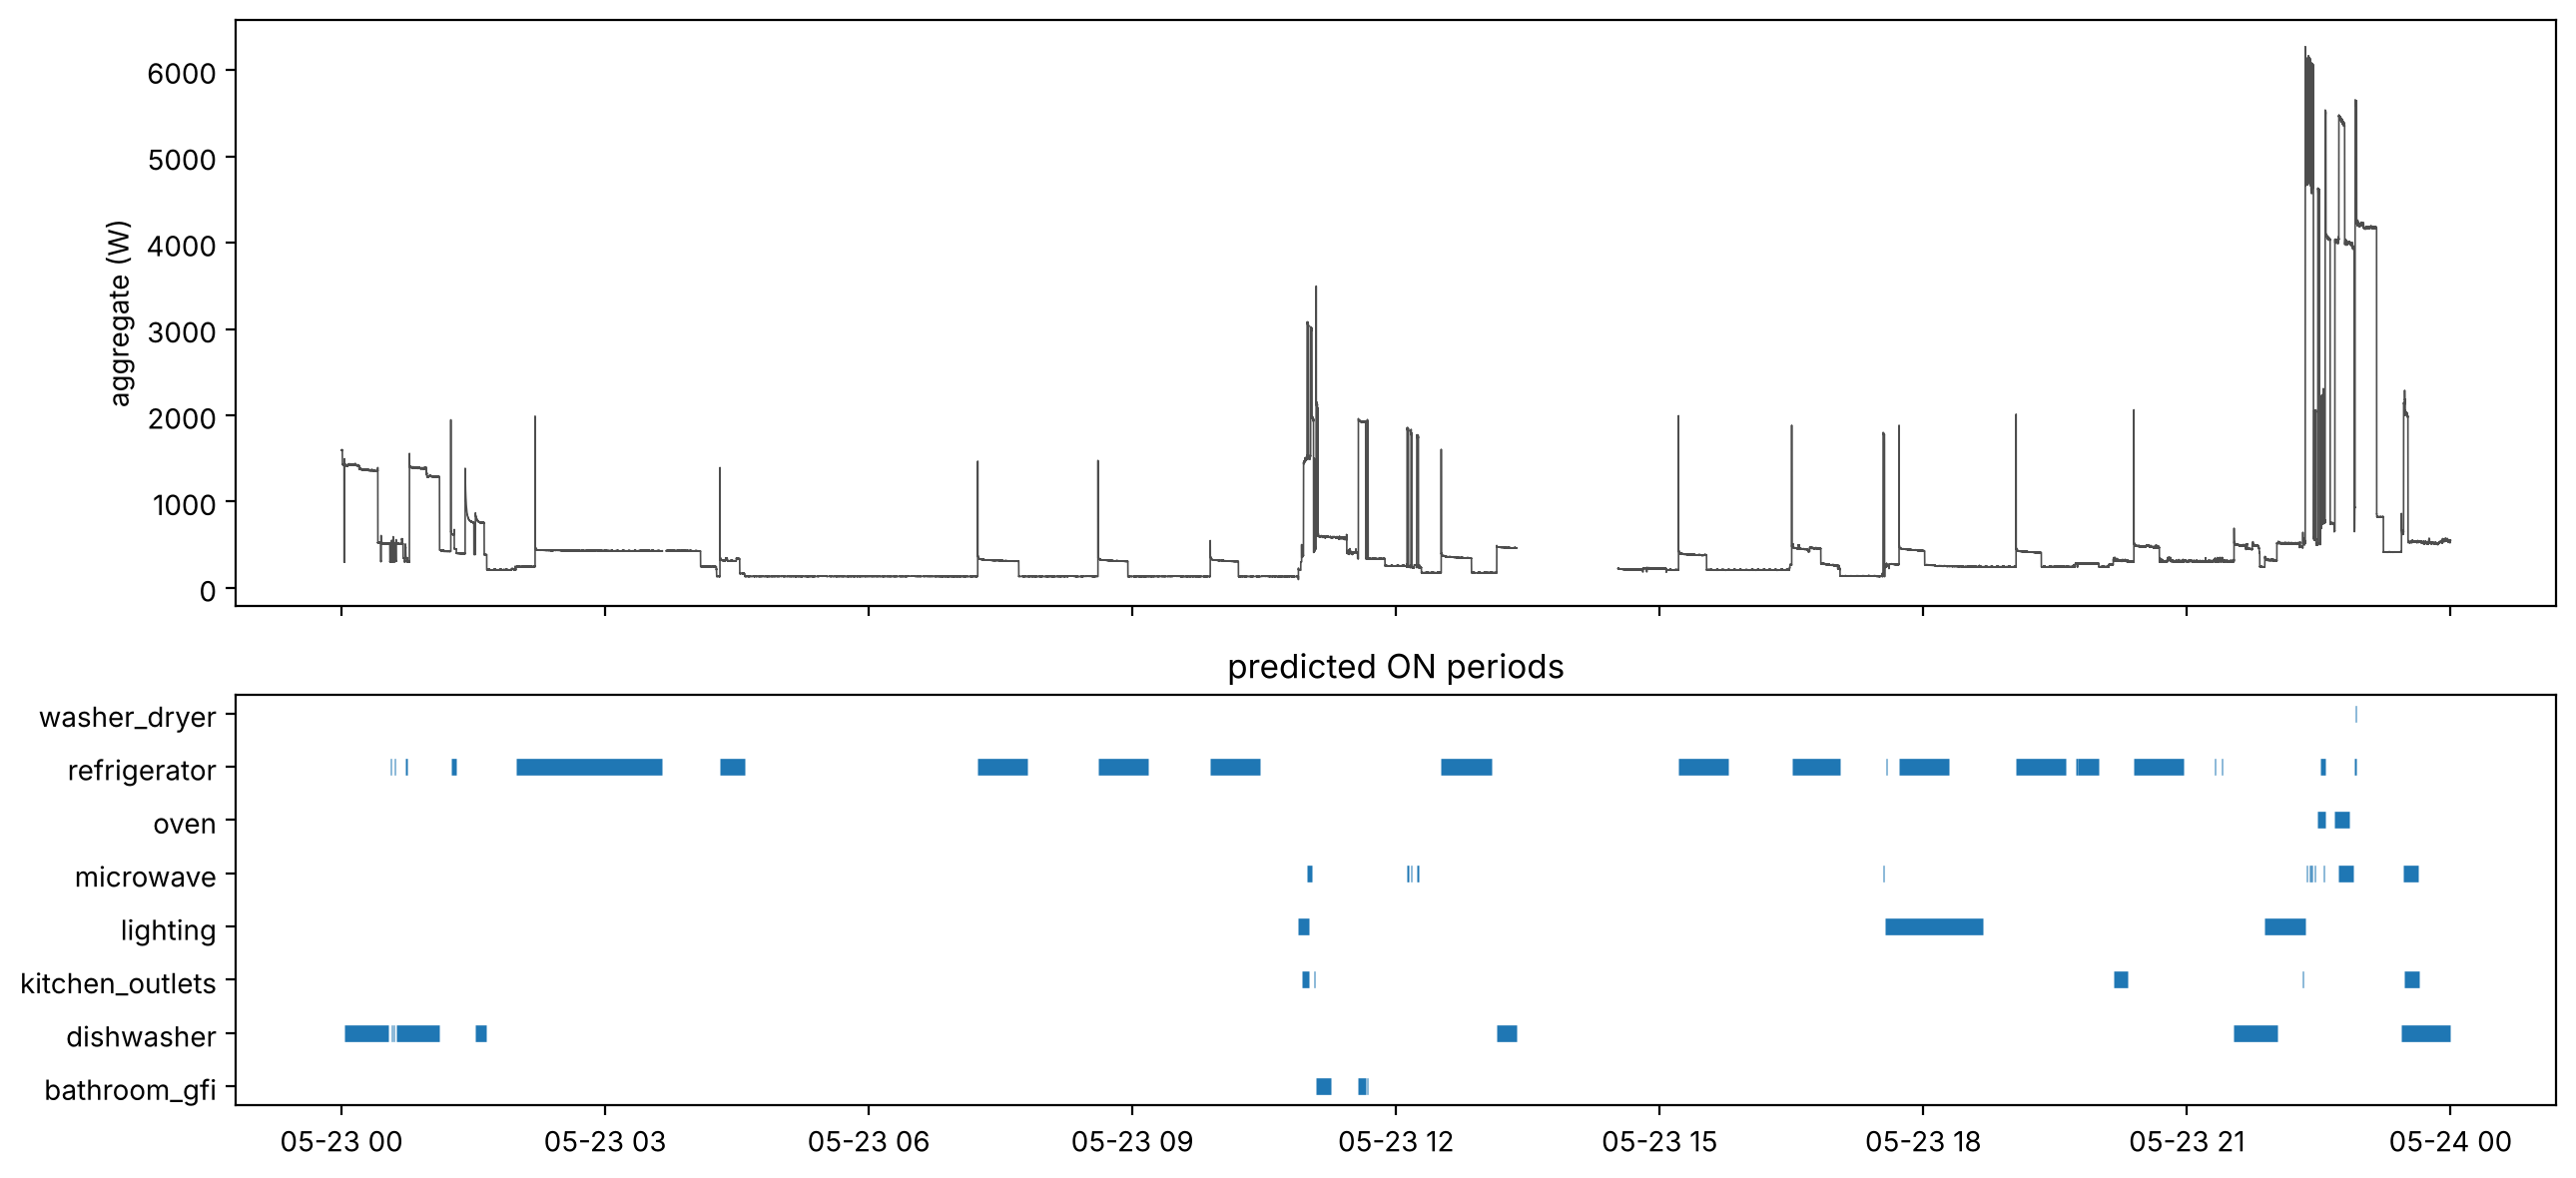

In [4]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 6), sharex=True, height_ratios=[2, 1.4])
ax1.plot(pd.to_datetime(agg.index, unit="s"), agg.to_numpy(), lw=0.6, color="0.3")
ax1.set_ylabel("aggregate (W)")
apps = sorted(on_periods.appliance.unique())
for i, a in enumerate(apps):
    g = on_periods[on_periods.appliance == a]
    off = g.off.fillna(pd.to_datetime(agg.index[-1], unit="s"))
    ax2.hlines([i] * len(g), g.on, off, lw=6)
ax2.set_yticks(range(len(apps)), apps)
ax2.set_title("predicted ON periods")
plt.tight_layout()

Check against the sub-meters (held-out data): `python scripts/check_predict_redd.py` writes
`results/predict_check/summary.json` and the per-appliance tables; see the README for the numbers.